# Лабораторная №1. Реализация линейной регрессии

Анализирую `RiskScore` и реализую нормализацию, линейную регрессию,
кросс-валидацию и метрики с помощью NumPy. Проверки со sklearn на тех же
данных и разбиениях находятся в `../solution/03_sklearn_comparison.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
import numpy as np
import pandas as pd

root = Path.cwd()

## Очистка данных

Два служебных значения `RiskScore` выходят за наблюдаемый диапазон шкалы.
Удаляю их вместе с отсутствующими целями, точными дублями и неполными
строками. Точные дубли могли бы попасть в разные фолды и занизить ошибку.

In [2]:
raw = pd.read_csv(root / "train.csv")
valid_target = raw.RiskScore.notna() & ~raw.RiskScore.isin([-9999999, 10000000])
valid = raw.loc[valid_target]
unique = valid.drop_duplicates()
data = unique.dropna().reset_index(drop=True)

display(pd.Series({
    "Исходных строк": len(raw),
    "Без корректной цели": len(raw) - len(valid),
    "Точных дублей среди строк с корректной целью": len(valid) - len(unique),
    "Неполных среди уникальных строк с корректной целью": len(unique) - len(data),
    "Осталось для анализа": len(data),
}, name="Строк"))

Исходных строк                                        11017
Без корректной цели                                     745
Точных дублей среди строк с корректной целью            484
Неполных среди уникальных строк с корректной целью      456
Осталось для анализа                                   9332
Name: Строк, dtype: int64

## Распределение `RiskScore`

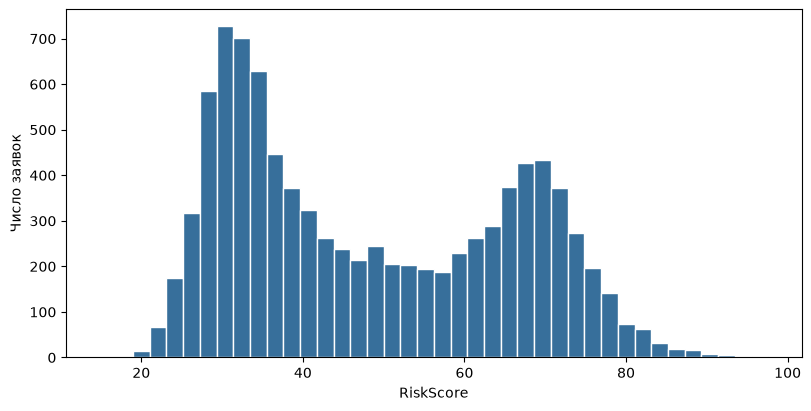

count    9332.00
mean       48.31
std        17.24
min        14.84
25%        32.69
50%        44.13
75%        65.06
max        97.60
Name: RiskScore, dtype: float64

In [3]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.hist(data.RiskScore, bins=40, color="#376F9B", edgecolor="white")
ax.set(xlabel="RiskScore", ylabel="Число заявок")
plt.show()

display(data.RiskScore.describe().round(2))

В распределении видны два выраженных пика. Поэтому полезно проверить
связи с `RiskScore` по всему диапазону, включая область между пиками.

## Зависимости признаков

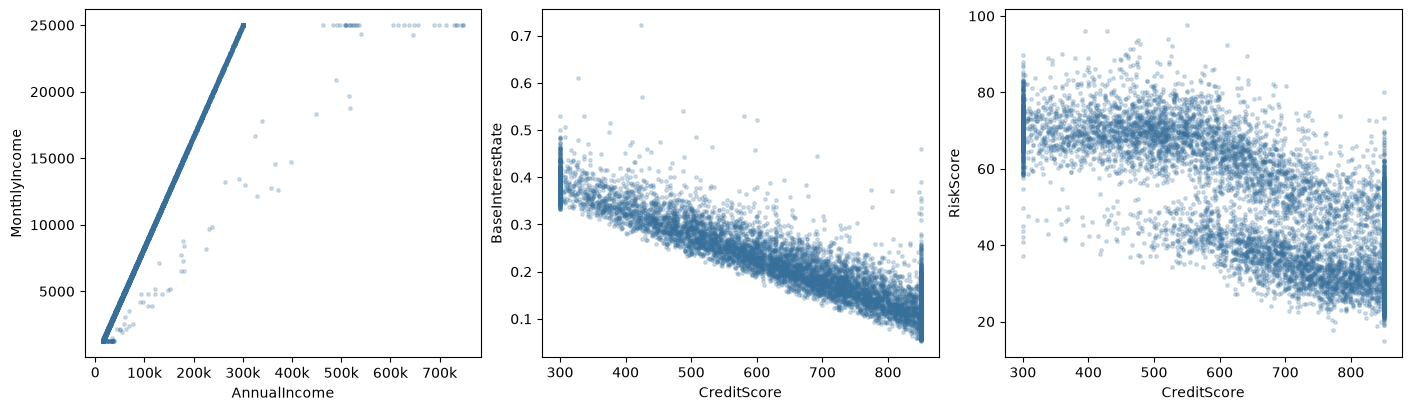

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
pairs = [
    ("AnnualIncome", "MonthlyIncome"),
    ("CreditScore", "BaseInterestRate"),
    ("CreditScore", "RiskScore"),
]
for ax, (x_name, y_name) in zip(axes, pairs):
    ax.scatter(data[x_name], data[y_name], s=6, alpha=0.22, color="#376F9B")
    ax.set(xlabel=x_name, ylabel=y_name)
axes[0].xaxis.set_major_formatter(EngFormatter(places=0, sep=""))
plt.show()

Месячный доход растёт почти пропорционально годовому и достигает потолка
25 000. При большем кредитном рейтинге базовая ставка и `RiskScore` обычно
ниже. При одинаковом `CreditScore` виден заметный разброс `RiskScore`,
поэтому в регрессию включаю и другие признаки.

## Матрица корреляций Пирсона

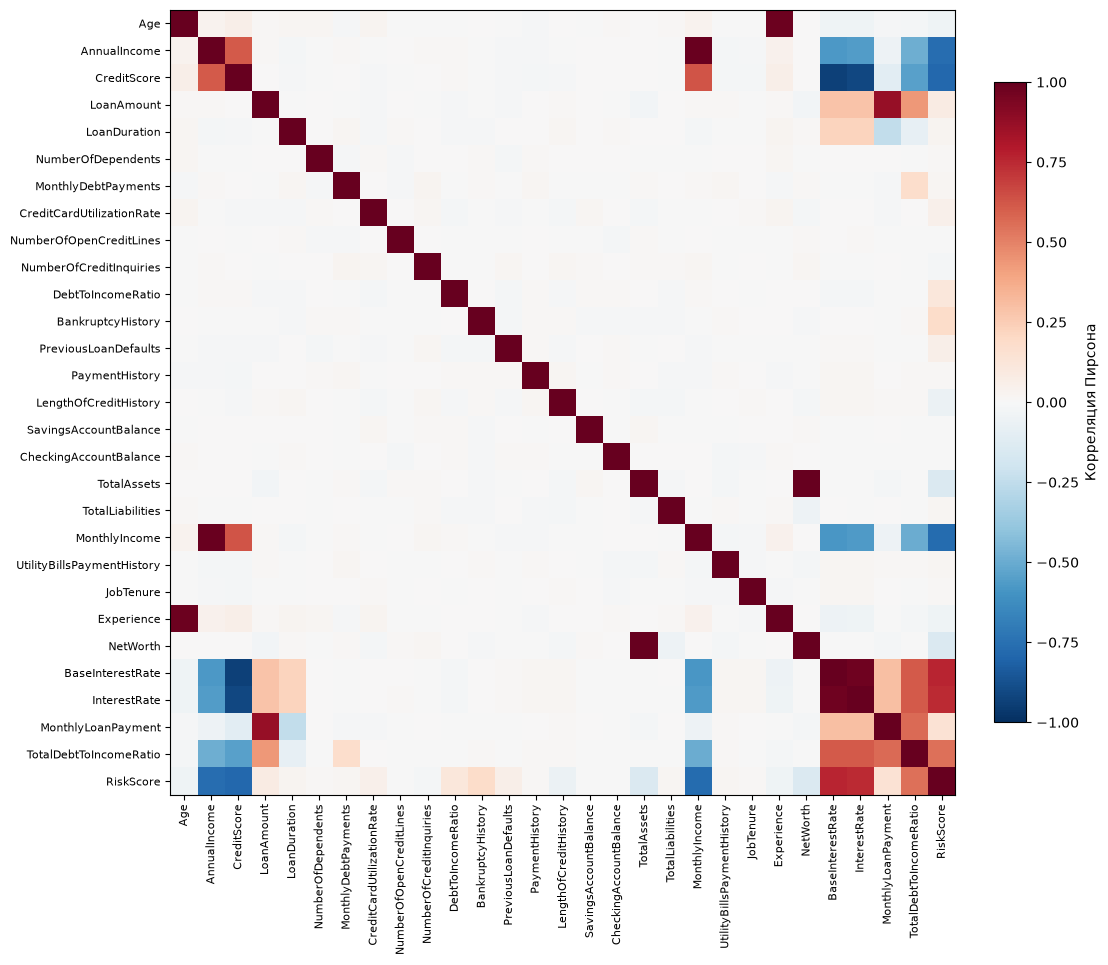

CreditScore              -0.785
MonthlyIncome            -0.770
BaseInterestRate          0.760
AnnualIncome             -0.758
InterestRate              0.744
TotalDebtToIncomeRatio    0.554
BankruptcyHistory         0.180
TotalAssets              -0.147
Name: RiskScore, dtype: float64

In [5]:
correlation = data.select_dtypes(include="number").corr()
positions = np.arange(len(correlation))
fig, ax = plt.subplots(figsize=(11, 10), layout="constrained")
heatmap = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(positions, correlation.columns, rotation=90, fontsize=8)
ax.set_yticks(positions, correlation.index, fontsize=8)
fig.colorbar(heatmap, ax=ax, shrink=0.75, label="Корреляция Пирсона")
plt.show()

target_correlations = correlation.RiskScore.drop("RiskScore")
display(target_correlations.sort_values(key=np.abs, ascending=False).head(8).round(3))

У `CreditScore` и дохода сильная отрицательная корреляция с `RiskScore`,
а у базовой и фактической ставок сильная положительная. Между доходами
и между ставками тоже сильная связь. При близкой линейной зависимости
признаков коэффициенты OLS могут быть неустойчивыми, поэтому перед
решением нормальных уравнений проверяю обусловленность матрицы.

## Z-score и min-max

Z-score вычитает среднее и делит на стандартное отклонение с делителем $n$.
Min-max вычитает минимум и делит на размах. У константных столбцов знаменатель
заменяю единицей, чтобы обучающие значения преобразовались в нули. Параметры
`fit` вычисляет по обучению, `transform` применяет их к новым данным.

In [6]:
import numpy as np


class MyStandardScaler:
    def fit(self, x):
        x = np.asarray(x, dtype=float)
        self.mean_ = x.mean(axis=0)
        scale = x.std(axis=0)
        self.scale_ = np.where(scale == 0, 1.0, scale)
        return self

    def transform(self, x):
        return (np.asarray(x, dtype=float) - self.mean_) / self.scale_

    def fit_transform(self, x):
        return self.fit(x).transform(x)


class MyMinMaxScaler:
    def fit(self, x):
        x = np.asarray(x, dtype=float)
        self.min_ = x.min(axis=0)
        span = x.max(axis=0) - self.min_
        self.range_ = np.where(span == 0, 1.0, span)
        return self

    def transform(self, x):
        return (np.asarray(x, dtype=float) - self.min_) / self.range_

    def fit_transform(self, x):
        return self.fit(x).transform(x)

## Метрики регрессии

Метрики считаю по остаткам $e_i=y_i-\hat y_i$.

- $\mathrm{MSE}=\frac{1}{n}\sum_i e_i^2$ сильнее штрафует большие ошибки.
- $\mathrm{MAE}=\frac{1}{n}\sum_i|e_i|$ измеряется в шкале `RiskScore`.
- $R^2=1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}$ сравнивает ошибки с
  прогнозом средним значением цели. При постоянной цели возвращаю 1 для
  точного прогноза и 0 для остальных, как sklearn по умолчанию.
- $\mathrm{MAPE}=\frac{1}{n}\sum_i\frac{|e_i|}{\max(|y_i|,\varepsilon)}$
  возвращает долю. Для процентов умножаю на 100. Машинное $\varepsilon$
  ограничивает снизу знаменатель при нулевой цели.

In [7]:
def my_mse(y, prediction):
    error = np.asarray(y, dtype=float) - np.asarray(prediction, dtype=float)
    return float(np.mean(error ** 2))


def my_mae(y, prediction):
    error = np.asarray(y, dtype=float) - np.asarray(prediction, dtype=float)
    return float(np.mean(np.abs(error)))


def my_r2(y, prediction):
    y = np.asarray(y, dtype=float)
    if len(y) < 2:
        return np.nan
    residual = np.sum((y - np.asarray(prediction, dtype=float)) ** 2)
    total = np.sum((y - y.mean()) ** 2)
    if total == 0:
        return float(residual == 0)
    return float(1 - residual / total)


def my_mape(y, prediction):
    y = np.asarray(y, dtype=float)
    error = np.abs(y - np.asarray(prediction, dtype=float))
    denominator = np.maximum(np.abs(y), np.finfo(float).eps)
    return float(np.mean(error / denominator))

## Класс линейной регрессии

`fit` оценивает коэффициенты $w$ и свободный член $b$, `predict` возвращает
$Xw+b$. Задача обучения минимизирует $J=\frac{1}{2n}\|Xw+b-y\|^2$.

- **Аналитически.** Центрирую $X$ и $y$ и получаю нормальное уравнение
  $X_c^T X_c w = X_c^T y_c$. Если матрица $X_c^T X_c$ обратима, то
  $w = (X_c^T X_c)^{-1} X_c^T y_c$. В коде решаю эту систему через
  `np.linalg.solve`. При вырожденной или плохо обусловленной матрице
  `np.linalg.lstsq` решает исходную задачу МНК по $X_c$ и $y_c$.
  Свободный член равен $b=\bar y-\bar X w$.
- **GD.** Один шаг использует полный градиент $X^T(\hat y-y)/n$ для весов
  и средний остаток $\operatorname{mean}(\hat y-y)$ для свободного члена.
- **SGD.** Перемешиваю строки в каждой эпохе и обновляю параметры после
  каждой строки. На шаге $t$ использую скорость $\eta_0/t^{0.5}$.

In [8]:
class MyLinearRegression:
    def __init__(self, method="analytical", learning_rate=0.05, epochs=200,
                 random_state=42):
        if method not in {"analytical", "gd", "sgd"}:
            raise ValueError("method must be analytical, gd or sgd")
        self.method = method
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state

    def fit(self, x, y):
        x = np.asarray(x, dtype=float)
        y = np.asarray(y, dtype=float)
        if x.ndim != 2 or y.shape != (len(x),) or len(x) == 0 or x.shape[1] == 0:
            raise ValueError("Expected a nonempty matrix X and one target per row")

        self.coef_ = np.zeros(x.shape[1])
        self.intercept_ = y.mean()
        if self.method == "analytical":
            self._fit_analytical(x, y)
        elif self.method == "gd":
            for _ in range(self.epochs):
                error = self.predict(x) - y
                self.coef_ -= self.learning_rate * (x.T @ error) / len(x)
                self.intercept_ -= self.learning_rate * error.mean()
        else:
            rng = np.random.default_rng(self.random_state)
            t = 1
            for _ in range(self.epochs):
                for row in rng.permutation(len(x)):
                    error = x[row] @ self.coef_ + self.intercept_ - y[row]
                    step = self.learning_rate / t ** 0.5
                    self.coef_ -= step * error * x[row]
                    self.intercept_ -= step * error
                    t += 1
        return self

    def _fit_analytical(self, x, y):
        x_mean, y_mean = x.mean(axis=0), y.mean()
        x_centered, y_centered = x - x_mean, y - y_mean
        gram = x_centered.T @ x_centered
        if np.linalg.cond(gram, p=1) < 1e8:
            self.coef_ = np.linalg.solve(gram, x_centered.T @ y_centered)
        else:
            self.coef_ = np.linalg.lstsq(x_centered, y_centered, rcond=None)[0]
        self.intercept_ = y_mean - x_mean @ self.coef_

    def predict(self, x):
        return np.asarray(x, dtype=float) @ self.coef_ + self.intercept_

## K-fold и leave-one-out

K-fold делит индексы на блоки примерно одинакового размера. Каждый блок
ровно один раз становится проверочным. В leave-one-out проверочный блок
состоит из одной строки. Модель и нормализация обучаются заново на каждом
разбиении. Прогнозы записываю на позиции исходных строк, чтобы затем
вычислить общую ошибку по предсказаниям вне обучения.

In [9]:
def my_k_fold(n_rows, n_splits=5, shuffle=True, random_state=42):
    if not 2 <= n_splits <= n_rows:
        raise ValueError("n_splits must be between 2 and n_rows")
    indices = np.arange(n_rows)
    if shuffle:
        np.random.RandomState(random_state).shuffle(indices)
    for validation in np.array_split(indices, n_splits):
        mask = np.ones(n_rows, dtype=bool)
        mask[validation] = False
        yield np.flatnonzero(mask), np.sort(validation)


def my_leave_one_out(n_rows):
    if n_rows < 2:
        raise ValueError("leave-one-out requires at least two rows")
    indices = np.arange(n_rows)
    for row in indices:
        yield np.r_[indices[:row], indices[row + 1:]], indices[row:row + 1]


def my_cross_val_predict(model_factory, x, y, splits, scaler_factory=None):
    x, y = np.asarray(x), np.asarray(y)
    prediction = np.full(len(y), np.nan)
    for train_idx, valid_idx in splits:
        x_train, x_valid = x[train_idx], x[valid_idx]
        if scaler_factory is not None:
            scaler = scaler_factory().fit(x_train)
            x_train, x_valid = scaler.transform(x_train), scaler.transform(x_valid)
        model = model_factory().fit(x_train, y[train_idx])
        prediction[valid_idx] = model.predict(x_valid)
    return prediction

## Проверка на примерах с известным ответом

Проверяю метрики вручную вычисленными значениями. Затем восстанавливаю
известную линейную зависимость тремя методами и проверяю прогнозы
k-fold и leave-one-out. Повторяю аналитическое обучение с дублирующим
столбцом, чтобы проверить случай вырожденной матрицы.

In [10]:
y_example, prediction = [1, 2, 4], [2, 2, 3]
np.testing.assert_allclose(
    [my_mse(y_example, prediction), my_mae(y_example, prediction),
     my_r2(y_example, prediction), my_mape(y_example, prediction)],
    [2 / 3, 2 / 3, 4 / 7, 5 / 12],
)
x_example = [[1, 7], [3, 7], [5, 7]]
np.testing.assert_allclose(MyMinMaxScaler().fit_transform(x_example), [[0, 0], [0.5, 0], [1, 0]])
z = MyStandardScaler().fit_transform(x_example)
np.testing.assert_allclose(z.mean(axis=0), [0, 0], atol=1e-12)
np.testing.assert_allclose(z.std(axis=0), [1, 0], atol=1e-12)

x_example = np.random.default_rng(42).normal(size=(100, 2))
y_example = 10 + x_example @ np.array([3, -2])
errors = {}
for method in ("analytical", "gd", "sgd"):
    model = MyLinearRegression(method, learning_rate=0.1, epochs=250).fit(x_example, y_example)
    errors[method] = my_mse(y_example, model.predict(x_example))
assert max(errors.values()) < 1e-8

x_dependent = np.column_stack([x_example, x_example[:, 0]])
model = MyLinearRegression().fit(x_dependent, y_example)
prediction = model.predict(x_dependent)
np.testing.assert_allclose(prediction, y_example, atol=1e-10, rtol=0)
errors["analytical, дублирующий столбец"] = my_mse(y_example, prediction)

for name, splits in (("k-fold", my_k_fold(len(y_example))),
                     ("leave-one-out", my_leave_one_out(len(y_example)))):
    prediction = my_cross_val_predict(MyLinearRegression, x_example, y_example, splits, MyStandardScaler)
    errors[name] = my_mse(y_example, prediction)
    np.testing.assert_allclose(prediction, y_example, atol=1e-10)
display(pd.Series(errors, name="MSE на примере с точной линейной связью"))

analytical                         4.654279e-31
gd                                 2.981646e-14
sgd                                1.240311e-17
analytical, дублирующий столбец    6.799981e-30
k-fold                             1.782826e-30
leave-one-out                      2.429692e-30
Name: MSE на примере с точной линейной связью, dtype: float64